<small>

### Library and Constant Values

</small>

In [ ]:
import numpy as np
import pandas as pd
import math
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, confusion_matrix
import xgboost as xgb
from xgboost import XGBRegressor
import optuna
import torch

<small>

### Data Acquisation

</small>

In [ ]:
# ML Dataset
red_wine_df = pd.read_csv("../dataset/winequality-red.csv", delimiter=";")
white_wine_df = pd.read_csv("../dataset/winequality-white.csv", delimiter=";")

red_wine_df.insert(
    loc=11,
    column="type",
    value="red",
    allow_duplicates=True
)
white_wine_df.insert(
    loc=11,
    column="type",
    value="white",
    allow_duplicates=True
)

wine_df = pd.concat([white_wine_df, red_wine_df], join="inner")

In [ ]:
wine_df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,type,quality
0,7.0,0.270,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,white,6
1,6.3,0.300,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,white,6
2,8.1,0.280,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,white,6
3,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,white,6
4,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,white,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,red,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,red,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,red,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,red,5


<small>

### Explanatory Data Analysis

</small>

<small>

#### Surface Level EDA

There are thirteen columns in the combine dataset with eleven numeric features, one categorical feature, and one label, details on each features and label are in the table below. Furthermore, dataset has 1147 duplicate data and outliers are found on every features and label. These issues need to be addressed on Data Preparation.  

| Attributes            | min   | median    | mean   | max   | mode   |
|-------------          |----   |-----      |----    |----   |----    |
| fixed acidity         | 3.8   | 7.0       | ~7.22  | 15.9  | -      |
| volatile acidity      | 0.08  | 0.29      | ~0.34  | 1.58  | -      |
| citric acid           | 0.0   | 7.0       | ~0.31  | 1.66  | -      |
| residual sugar        | 0.6   | 3.0       | ~5.44  | 65.8  | -      |
| chlorides             | 0.009 | 0.047     | ~0.05  | 0.611 | -      |
| free sulfur dioxide   | 1.0   | 29.0      | ~30.5  | 289.0 | -      |
| total sulfur dioxide  | 6.0   | 118.0     | ~115.7 | 440.0 | -      |
| density               | 0.987 | 0.995     | ~0.995 | ~1.04 | -      |
| pH                    | 2.72  | 3.21      | ~3.22  | 4.01  | -      |
| sulphates             | 0.22  | 0.51      | ~0.53  | 2.0   | -      |
| alcohol               | 8.0   | 10.3      | ~10.49 | 14.9  | -      |
| type                  | -     | -         | -      | -     | white  |
| quality               | 3.0   | 6.0       | ~5.8   | 9.0   | -      |

##### Outlier Summary

Outliers were counted on the deduplicated dataset (5320 rows) with three rules: the IQR rule over the whole dataset (pooled), the IQR rule computed separately for red and white wine (per type), and z-score > 5 for truly extreme values. `quality` is the label and is not included.

| Feature               | IQR pooled | IQR per type | z-score > 5 | skew  | p99    | max     |
|-------------          |----        |----          |----         |----   |----    |----     |
| fixed acidity         | 304        | 147          | 8           | 1.65  | 12.0   | 15.9    |
| volatile acidity      | 279        | 152          | 4           | 1.50  | 0.889  | 1.58    |
| citric acid           | 143        | 224          | 2           | 0.48  | 0.74   | 1.66    |
| residual sugar        | 141        | 142          | 2           | 1.71  | 18.15  | 65.8    |
| chlorides             | 237        | 265          | 32          | 5.34  | 0.2    | 0.611   |
| free sulfur dioxide   | 44         | 70           | 7           | 1.36  | 76.0   | 289.0   |
| total sulfur dioxide  | 10         | 59           | 1           | 0.06  | 240.0  | 440.0   |
| density               | 3          | 41           | 2           | 0.67  | 1.001  | 1.039   |
| pH                    | 49         | 74           | 0           | 0.39  | 3.65   | 4.01    |
| sulphates             | 163        | 151          | 13          | 1.81  | 1.02   | 2.0     |
| alcohol               | 1          | 12           | 0           | 0.55  | 13.4   | 14.9    |

Key findings:
- 1094 rows (20.6%) have at least one pooled IQR outlier. Removing them would also remove 20 of the 30 quality-3 wines and 18 of the 148 quality-8 wines, so dropping every outlier is not an option.
- Many pooled outliers come from the red vs white difference, not from bad values (e.g. fixed acidity drops from 304 to 147 when computed per type). IQR should be computed per `type`.
- Only a few values are truly extreme and may be data errors: residual sugar 65.8 (p99 18.15), free sulfur dioxide 289 (p99 76), density 1.039 (p99 1.001).
- Chlorides, sulphates, residual sugar, fixed acidity, and volatile acidity are right-skewed (skew > 1.4); a log transform is more suitable than removal.
- Outliers on `quality` (3 and 9) are real scores and are kept.

</small>

<small>

##### Helper

</small>

In [ ]:
def plot_outlier(df: pd.DataFrame, columns: list[str] | None = None, max_plot_cols: int = 3):    
    if columns is None:
        columns = list(df.select_dtypes(include=['number']).columns)
    
    num_plots = len(columns)
    if num_plots == 0:
        print("ValueError: Dataframe has no columns")
        return
    
    n_cols = min(max_plot_cols, num_plots)
    n_rows = math.ceil(num_plots / n_cols)
    
    fig, axes = plt.subplots(
        nrows=n_rows,
        ncols=n_cols,
        figsize=(n_cols * 4, n_rows * 4)
    )
    
    axes = axes.flatten() if num_plots > 1 else [axes]
    
    for idx, col in enumerate(columns):
        sns.boxplot(ax=axes[idx], x=df[col])
        axes[idx].set_title(f"Outliers in {col.title()}", fontsize=12)
        axes[idx].set_xlabel("")
    
    for idx in range (num_plots, len(axes)):
        fig.delaxes(axes[idx])
    
    plt.tight_layout()
    plt.show()

In [ ]:
def iqr_outlier_mask(series: pd.Series, k: float = 1.5) -> pd.Series:
    """True where a value falls outside [Q1 - k*IQR, Q3 + k*IQR]."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (series < q1 - k * iqr) | (series > q3 + k * iqr)


def outlier_summary(
    df: pd.DataFrame,
    group_col: str = "type",
    exclude: list[str] | None = None,
    z_threshold: float = 5.0,
) -> tuple[pd.DataFrame, pd.Series]:
    """
    Per-feature outlier counts with three rules:
      - IQR pooled:    IQR rule over the whole dataset
      - IQR per group: IQR rule computed separately inside each `group_col` value (e.g. red vs white)
      - |z| > z_threshold: only truly extreme values
    Also returns a row mask: True if the row has at least one pooled-IQR outlier.
    """
    exclude = ["quality"] if exclude is None else exclude
    df = df.reset_index(drop=True)
    features = [col for col in df.select_dtypes(include=["number"]).columns if col not in exclude]

    rows = []
    any_outlier = pd.Series(False, index=df.index)
    for col in features:
        series = df[col]
        pooled_mask = iqr_outlier_mask(series)
        per_group_mask = df.groupby(group_col)[col].transform(iqr_outlier_mask).astype(bool)
        z_scores = (series - series.mean()) / series.std()
        any_outlier |= pooled_mask

        rows.append({
            "feature": col,
            "IQR pooled": int(pooled_mask.sum()),
            f"IQR per {group_col}": int(per_group_mask.sum()),
            f"|z| > {z_threshold:g}": int((z_scores.abs() > z_threshold).sum()),
            "skew": round(series.skew(), 2),
            "p99": round(series.quantile(0.99), 3),
            "max": series.max(),
        })

    return pd.DataFrame(rows).set_index("feature"), any_outlier

<small>

##### Main

</small>

In [ ]:
wine_df.describe(include='all')

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,type,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497,6497.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,white,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4898,NaN
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,NaN,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,NaN,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,NaN,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,NaN,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,NaN,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,NaN,6.000000


In [ ]:
# Duplicated Data
wine_df[wine_df.duplicated()]

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,type,quality
4,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,white,6
5,8.1,0.280,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,white,6
7,7.0,0.270,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,white,6
8,6.3,0.300,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,white,6
20,6.2,0.660,0.48,1.2,0.029,29.0,75.0,0.98920,3.33,0.39,12.8,white,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1563,7.2,0.695,0.13,2.0,0.076,12.0,20.0,0.99546,3.29,0.54,10.1,red,5
1564,7.2,0.695,0.13,2.0,0.076,12.0,20.0,0.99546,3.29,0.54,10.1,red,5
1567,7.2,0.695,0.13,2.0,0.076,12.0,20.0,0.99546,3.29,0.54,10.1,red,5
1581,6.2,0.560,0.09,1.7,0.053,24.0,32.0,0.99402,3.54,0.60,11.3,red,5


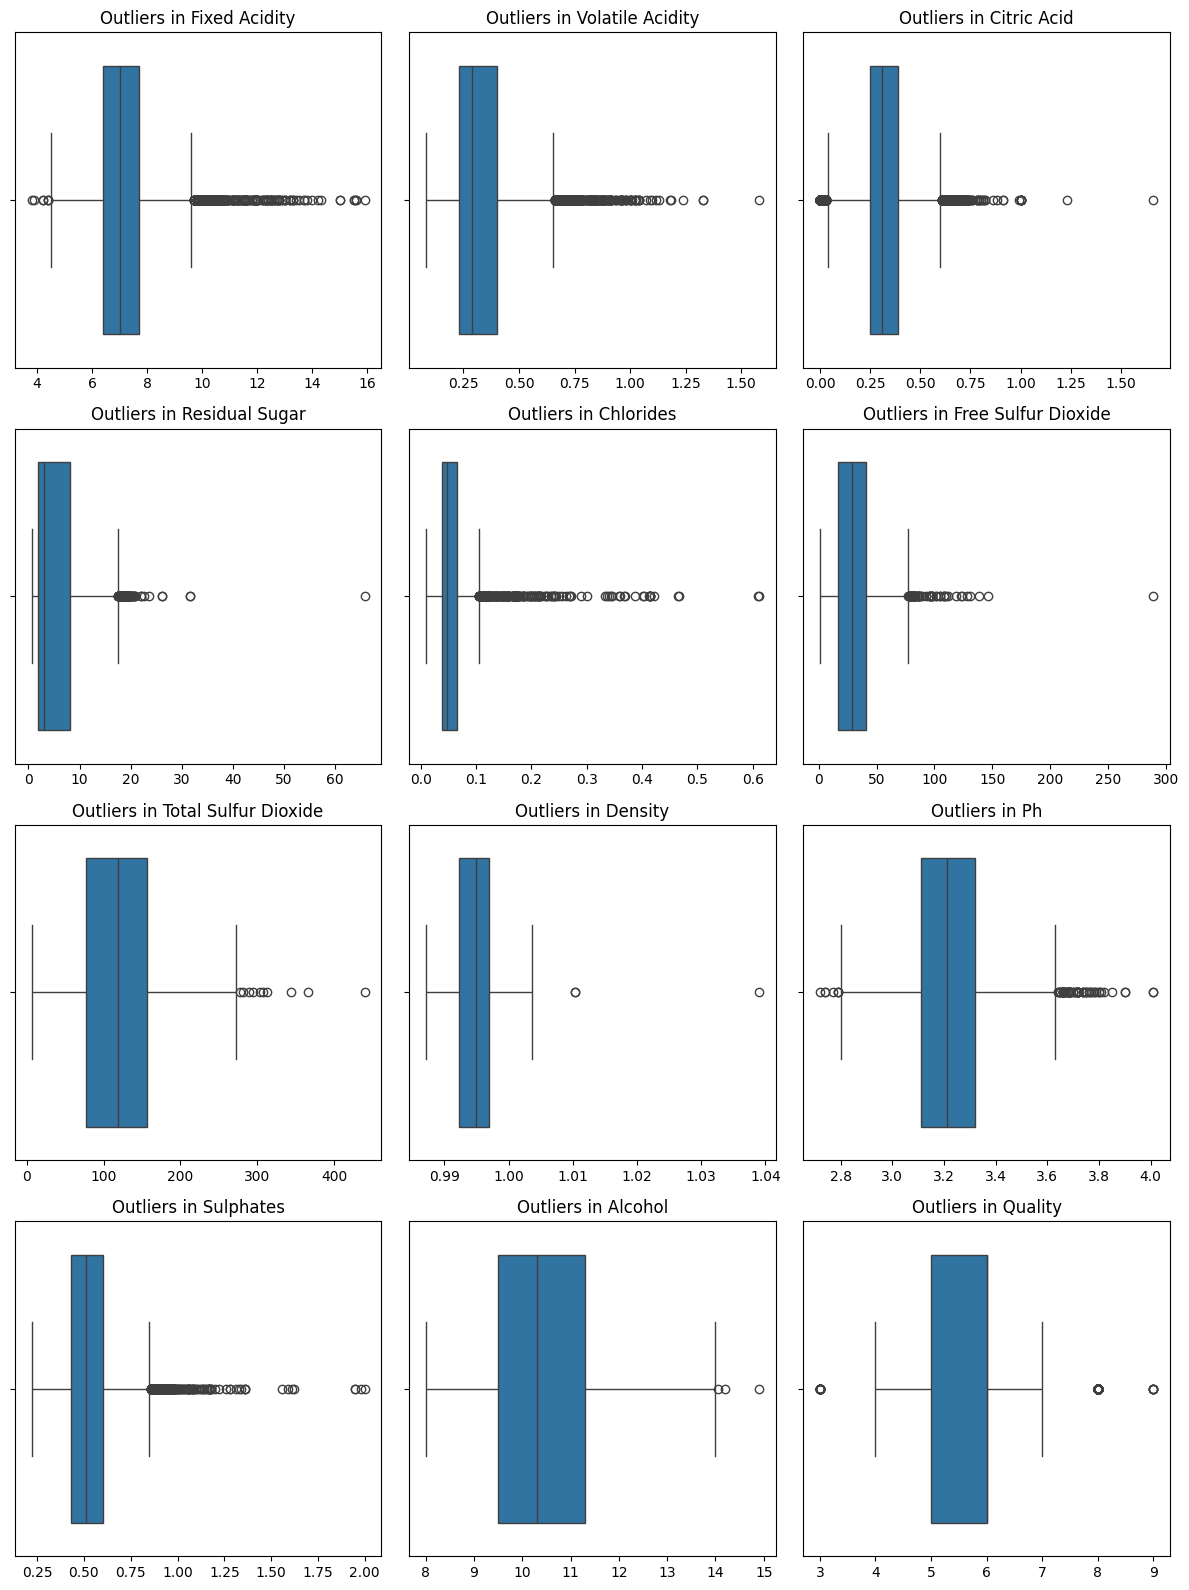

In [ ]:
# Outlier Data
plot_outlier(df=wine_df)

In [ ]:
# Outlier Summary (on deduplicated data)
dedup_df = wine_df.drop_duplicates().reset_index(drop=True)
outlier_table, has_outlier = outlier_summary(dedup_df)

print(f"Rows after dedup: {len(dedup_df)}")
print(f"Rows with >= 1 pooled IQR outlier: {has_outlier.sum()} ({has_outlier.mean():.1%})")
print("Quality counts (all rows):        ", dedup_df["quality"].value_counts().sort_index().to_dict())
print("Quality counts (rows w/ outlier): ", dedup_df.loc[has_outlier, "quality"].value_counts().sort_index().to_dict())

outlier_table

Rows after dedup: 5320
Rows with >= 1 pooled IQR outlier: 1094 (20.6%)
Quality counts (all rows):         {3: 30, 4: 206, 5: 1752, 6: 2323, 7: 856, 8: 148, 9: 5}
Quality counts (rows w/ outlier):  {3: 20, 4: 57, 5: 461, 6: 421, 7: 117, 8: 18}


,IQR pooled,IQR per type,|z| > 5,skew,p99,max
feature,,,,,,
fixed acidity,304,147,8,1.65,12.000,15.90000
volatile acidity,279,152,4,1.50,0.889,1.58000
citric acid,143,224,2,0.48,0.740,1.66000
residual sugar,141,142,2,1.71,18.150,65.80000
chlorides,237,265,32,5.34,0.200,0.61100
free sulfur dioxide,44,70,7,1.36,76.000,289.00000
total sulfur dioxide,10,59,1,0.06,240.000,440.00000
density,3,41,2,0.67,1.001,1.03898
pH,49,74,0,0.39,3.650,4.01000


<small>

#### Deep Level EDA

On distribution plots, dataset was splitted into three, such as bad wine, good wine, and great wine. This is based on the `quality` feature in the dataset.
| Wine Taste            | Range     |
|-------------          |----       |
| Bad Quality           | <= 5      |
| Good Quality          | 5 < x < 7 |
| Great Quality         | >= 7      |

The distribution plots show that it has no real feature that could differentiate fully between the three `wine_taste`, except `alcohol`. `alcohol` shows it could differentiate it, but not cleanly.

Furthermore, correlation was employed to show the correlation each features against the label. The result are no features have significant correlation. The highest are `alcohol` with 44%, which already suggested by distribution plots earlier.
</small>

<small>

##### Helper

</small>

In [ ]:
TASTE_ORDER = ["Bad Quality", "Good Quality", "Great Quality"]
TASTE_PALETTE = {"Bad Quality": "#2a78d6", "Good Quality": "#eb6834", "Great Quality": "#1baf7a"}

def plot_distribution(df: pd.DataFrame, columns: list[str] | None = None, max_plot_cols: int = 2):
    df = df.reset_index(drop=True).copy()
    df["wine_taste"] = pd.cut(
        df["quality"],
        bins=[0, 5, 7, 10],
        labels=TASTE_ORDER,
        include_lowest=True
    )

    if columns is None:
        columns = [col for col in df.select_dtypes(include=["number"]).columns if col != "quality"]

    num_plots = len(columns)
    if num_plots == 0:
        print("ValueError: Dataframe has no columns")
        return

    n_cols = min(max_plot_cols, num_plots)
    n_rows = math.ceil(num_plots / n_cols)

    fig, axes = plt.subplots(
        nrows=n_rows,
        ncols=n_cols,
        figsize=(n_cols * 5, n_rows * 3.5)
    )

    axes = axes.flatten() if num_plots > 1 else [axes]

    for idx, column in enumerate(columns):
        sns.kdeplot(
            data=df,
            x=column,
            hue="wine_taste",
            hue_order=TASTE_ORDER,
            ax=axes[idx],
            fill=True,
            common_norm=False,
            palette=TASTE_PALETTE,
            alpha=0.25,
            linewidth=2,
            legend=False
        )
        axes[idx].set_title(f"{column.title()} Distribution", fontsize=12)
        axes[idx].set_xlabel("")
        axes[idx].set_ylabel("")

    for idx in range(num_plots, len(axes)):
        fig.delaxes(axes[idx])

    counts = df["wine_taste"].value_counts()
    handles = [plt.Line2D([], [], color=TASTE_PALETTE[t], linewidth=6) for t in TASTE_ORDER] # type: ignore
    labels = [f"{t} (n={counts[t]})" for t in TASTE_ORDER]
    fig.legend(handles, labels, loc="upper center", ncol=len(TASTE_ORDER), frameon=False, bbox_to_anchor=(0.5, 1.02))

    plt.tight_layout()
    plt.show()

<small>

##### Main

</small>

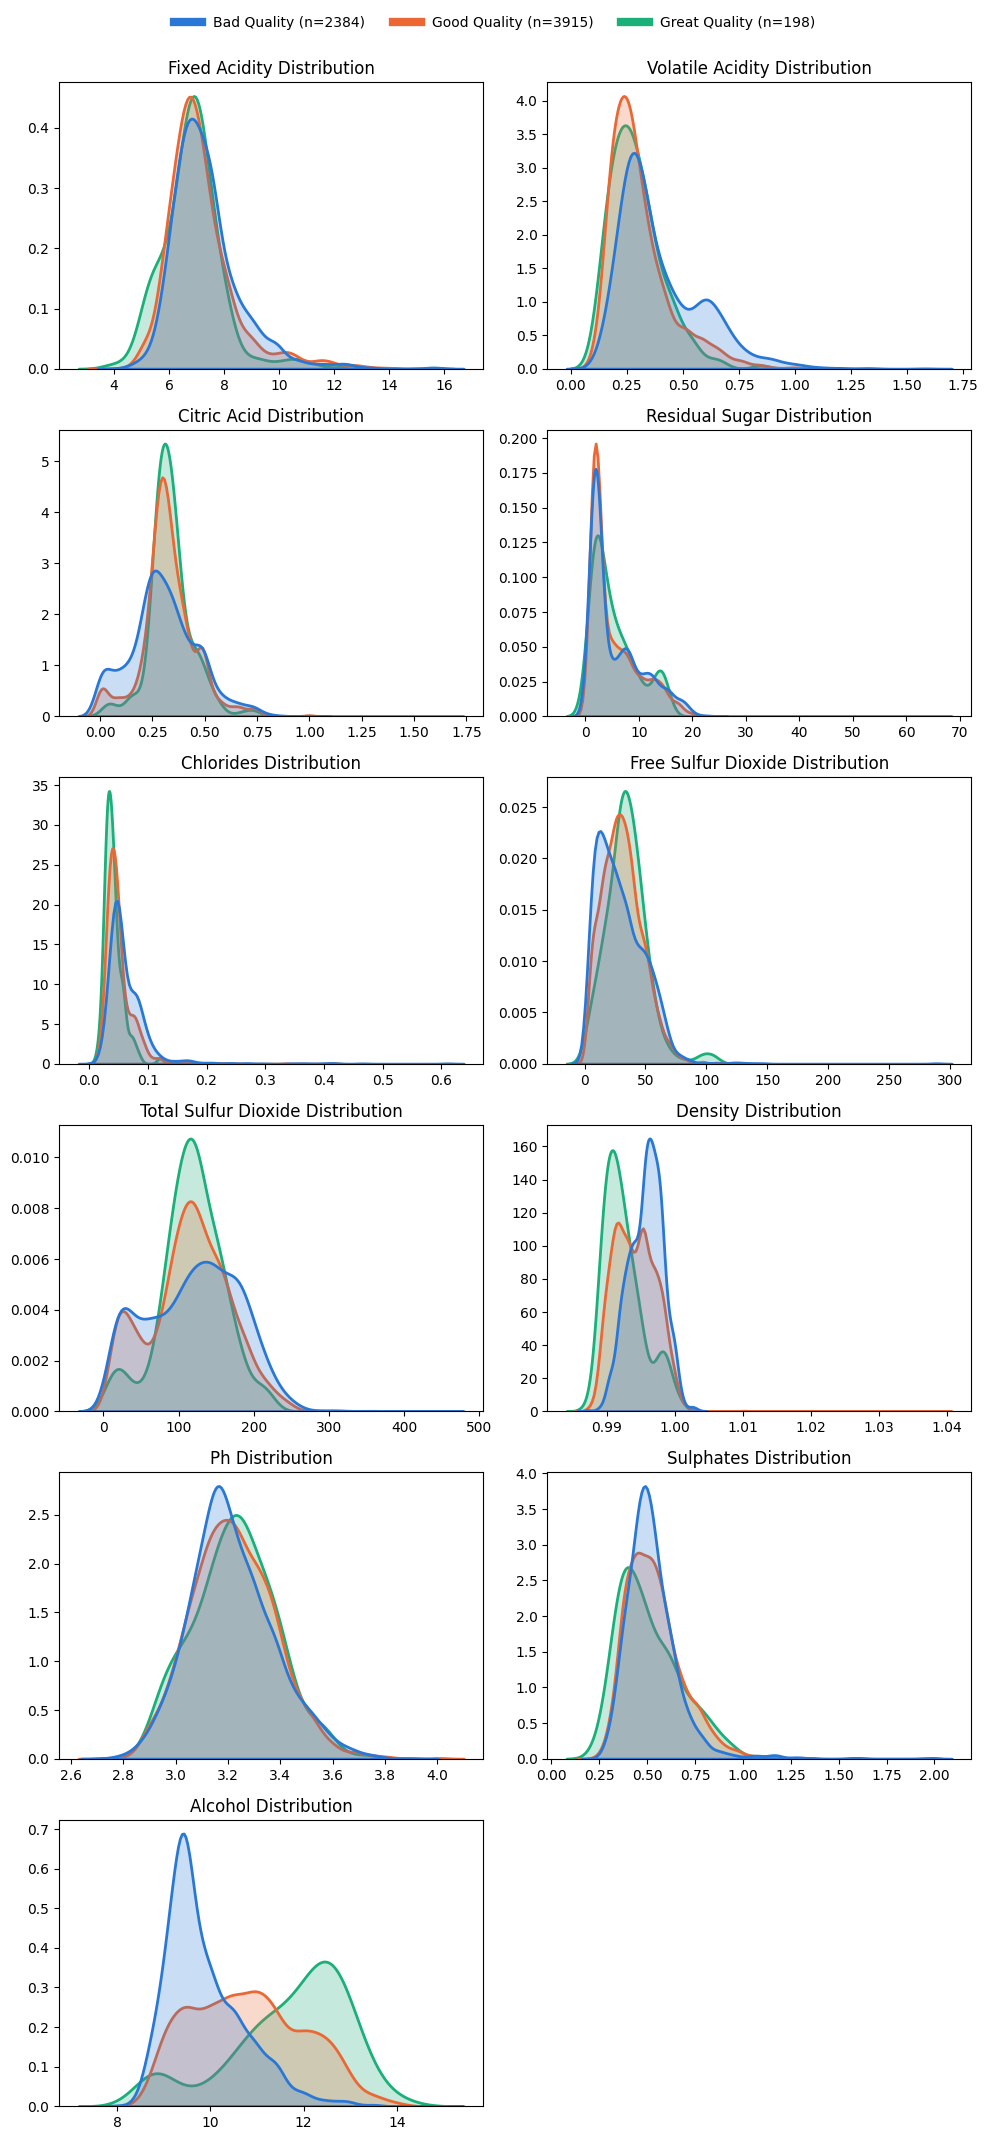

In [ ]:
plot_distribution(wine_df)

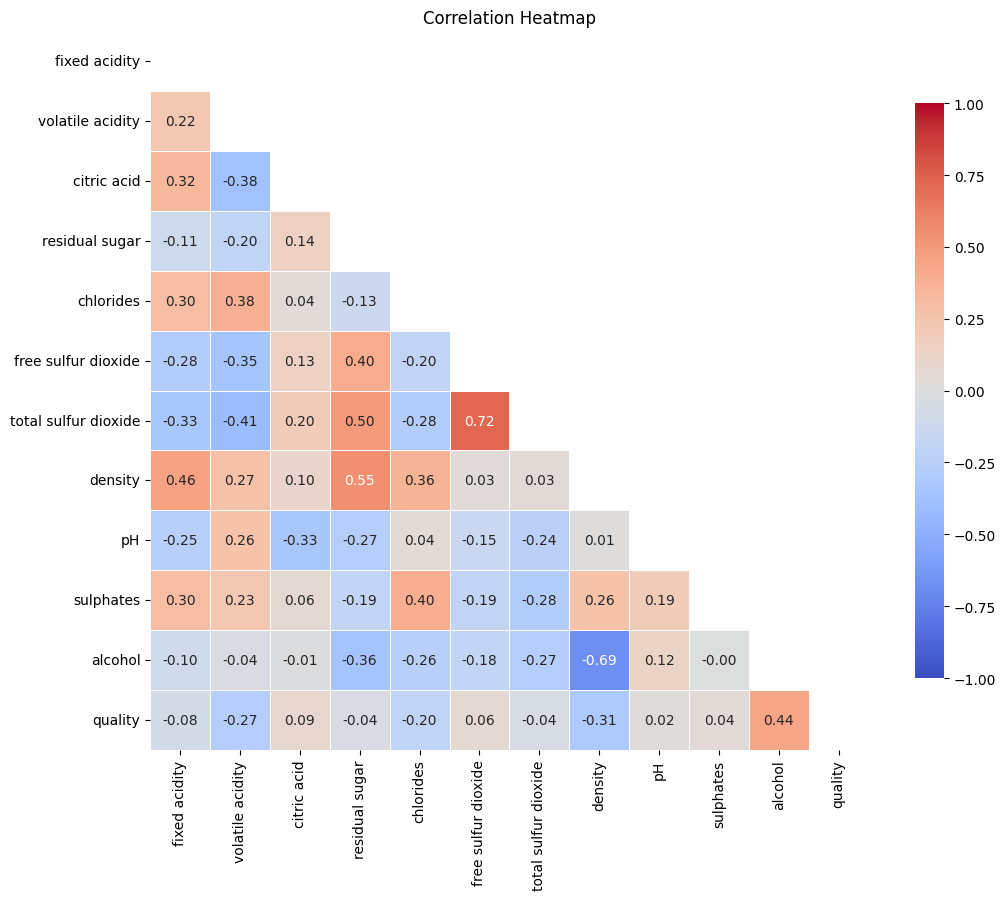

In [ ]:
corr = wine_df.select_dtypes(include="number").corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(11, 9))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1, center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": 0.8},
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

<small>

### Data Prepraration

</small>

<small>

#### Duplicate Handling

</small>

In [ ]:
wine_df = wine_df.drop_duplicates()
wine_df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,type,quality
0,7.0,0.270,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,white,6
1,6.3,0.300,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,white,6
2,8.1,0.280,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,white,6
3,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,white,6
6,6.2,0.320,0.16,7.0,0.045,30.0,136.0,0.99490,3.18,0.47,9.6,white,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1593,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,red,6
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,red,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,red,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,red,5


<small>

#### Outlier Handling and Data Splitting

</small>

In [ ]:
extreme = (
    (wine_df["residual sugar"] > 30)
    | (wine_df["free sulfur dioxide"] > 200)
    | (wine_df["density"] > 1.01)
)
wine_df = wine_df[~extreme]

X = wine_df.drop(["type", "quality"], axis=1)
y = wine_df.quality
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

skewed = ["chlorides", "sulphates", "residual sugar", "fixed acidity", "volatile acidity", "free sulfur dioxide"]
X_train[skewed] = np.log1p(X_train[skewed])
X_test[skewed]  = np.log1p(X_test[skewed])

low  = X_train.quantile(0.01)
high = X_train.quantile(0.99)
X_train = X_train.clip(low, high, axis=1)
X_test  = X_test.clip(low, high, axis=1)

scaler = RobustScaler().fit(X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)

<small>

### Modelling and Training

</small>